# 04 — Topic Modeling (LDA & NMF)

> **Purpose** — Discover latent themes in the CTI corpus using two unsupervised techniques: **Latent Dirichlet Allocation (LDA)** and **Non-negative Matrix Factorization (NMF)**. Topics are used downstream for temporal analysis and emerging-threat scoring.

<span class="badge badge-blue">Unsupervised</span><span class="badge badge-green">LDA</span><span class="badge badge-orange">NMF</span><span class="badge badge-red">Coherence</span>

## Table of Contents

1. [Setup & Imports](#1-setup--imports)
2. [Load Cleaned Dataset](#2-load-cleaned-dataset)
3. [Choose Number of Topics](#3-choose-number-of-topics)
4. [Train LDA](#4-train-lda)
5. [Train NMF](#5-train-nmf)
6. [Side-by-Side Topic Comparison](#6-side-by-side-topic-comparison)
7. [Topic Coherence Analysis](#7-topic-coherence-analysis)
8. [Document-Topic Distribution](#8-document-topic-distribution)
9. [Topic Prevalence](#9-topic-prevalence)
10. [Topic ↔ Category Alignment](#10-topic--category-alignment)
11. [Visualizations](#11-visualizations)
12. [Save Models & Topics](#12-save-models--topics)
13. [Summary](#13-summary)


## 1. Setup & Imports

In [1]:
import sys, pathlib, time
sys.path.append(str(pathlib.Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF

from src.config import (OUTPUT_DIR, MODELS_DIR, TOPICS_DIR,
                        FIGURES_DIR, N_TOPICS, TOP_N_WORDS,
                        RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print('N_TOPICS    :', N_TOPICS)
print('TOP_N_WORDS :', TOP_N_WORDS)
print('Random state:', RANDOM_STATE)

N_TOPICS    : 10
TOP_N_WORDS : 10
Random state: 42


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv(OUTPUT_DIR / 'cleaned_cti.csv')
print('Loaded:', df.shape)

text_col = 'clean_full' if 'clean_full' in df.columns else 'clean_text'
print('Using text column:', text_col)

docs = df[text_col].astype(str).tolist()
print('Documents:', len(docs))
print()
print('Sample document:')
print(docs[0][:300])

Loaded: (10000, 23)
Using text column: clean_text
Documents: 10000

Sample document:
recent threat campaign involved ddos activity against retail sector. initial access linked drive-by download. analyst observed distributed denial service additional activity associated with silverworm. campaign affected system japan classified high severity. observed vulnerability identifier cve-202


## 3. Choose Number of Topics

Train LDA with a range of K values and pick the K that maximizes topic coherence (or minimizes perplexity). Run this once, then fix K for the rest of the notebook.

In [3]:
K_RANGE = [4, 6, 8, 10, 12, 15]

vec_counts = CountVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)
X_counts = vec_counts.fit_transform(docs)
print('Count matrix:', X_counts.shape)

lda_scores = []
for k in K_RANGE:
    t0 = time.time()
    lda = LatentDirichletAllocation(
        n_components=k, random_state=RANDOM_STATE,
        learning_method='batch', max_iter=15
    )
    lda.fit(X_counts)
    perplexity = lda.perplexity(X_counts)
    lda_scores.append({
        'K': k,
        'Perplexity': round(perplexity, 1),
        'TimeSec': round(time.time() - t0, 1),
    })
    print(f'K={k:2d}  perplexity={perplexity:8.1f}  time={lda_scores[-1]["TimeSec"]}s')

lda_scores_df = pd.DataFrame(lda_scores)
lda_scores_df

Count matrix: (10000, 2385)
K= 4  perplexity=   214.4  time=56.0s
K= 6  perplexity=   217.7  time=62.1s
K= 8  perplexity=   211.5  time=80.9s
K=10  perplexity=   212.1  time=87.6s
K=12  perplexity=   210.5  time=93.1s
K=15  perplexity=   209.9  time=94.4s


,K,Perplexity,TimeSec
0,4,214.4,56.0
1,6,217.7,62.1
2,8,211.5,80.9
3,10,212.1,87.6
4,12,210.5,93.1
5,15,209.9,94.4


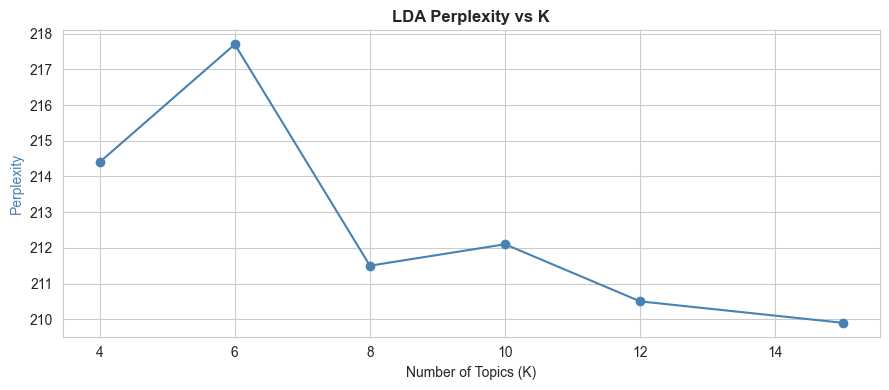

In [4]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(lda_scores_df['K'], lda_scores_df['Perplexity'],
         marker='o', color='steelblue')
ax1.set_xlabel('Number of Topics (K)')
ax1.set_ylabel('Perplexity', color='steelblue')
ax1.set_title('LDA Perplexity vs K', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_lda_perplexity.png')
plt.show()

<div class="callout"><b>Choosing K:</b> Lower perplexity is better, but interpretability matters too. If K=10 was set in <code>src/config.py</code>, compare it against this plot before overriding.</div>

## 4. Train LDA

LDA is a generative probabilistic model. Each document is modeled as a mixture of topics; each topic is a distribution over words.

In [5]:
print(f'Training LDA with K={N_TOPICS}...')
t0 = time.time()
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    learning_method='batch',
    max_iter=20,
)
lda_model.fit(X_counts)
print(f'  Time: {time.time()-t0:.2f}s')

vocab_lda = vec_counts.get_feature_names_out()
def top_words(components, vocab, n=TOP_N_WORDS):
    result = []
    for row in components:
        idx = np.argsort(row)[::-1][:n]
        result.append([vocab[i] for i in idx])
    return result

lda_topics = top_words(lda_model.components_, vocab_lda)
for i, terms in enumerate(lda_topics):
    print(f"LDA Topic {i:2d}: {', '.join(terms)}")


Training LDA with K=10...
  Time: 105.97s
LDA Topic  0: campaign, activity, additional, observed, vulnerability, access, threat, observed vulnerability, cve, included
LDA Topic  1: observed, during, during investigation, investigation, threat, vulnerability, file, cve, network, included network
LDA Topic  2: ddos, flood, identified ddos, ddos incident, http flood, http, flood followed, included http, 58076 additional, 58076
LDA Topic  3: campaign, additional, activity, observed, vulnerability, access, observed vulnerability, cve, recent threat, recent
LDA Topic  4: activity, investigation, observed, file, vulnerability, observed vulnerability, security, campaign, cve, network
LDA Topic  5: investigation, activity, observed, network, vulnerability, file, security, observed vulnerability, campaign, cve
LDA Topic  6: during investigation, during, investigation, observed, campaign, vulnerability, network, detected, campaign used, sector researcher
LDA Topic  7: included, activity, observed

## 5. Train NMF

NMF factorizes the TF-IDF matrix into two non-negative matrices (document-topic and topic-term). It tends to produce more interpretable, part-based topics than LDA.

In [6]:
print(f'Training NMF with K={N_TOPICS}...')
vec_tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)
X_tfidf = vec_tfidf.fit_transform(docs)
print('TF-IDF matrix:', X_tfidf.shape)

t0 = time.time()
nmf_model = NMF(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    init='nndsvd',
    max_iter=400,
)
nmf_model.fit(X_tfidf)
print(f'  Time: {time.time()-t0:.2f}s')

vocab_nmf = vec_tfidf.get_feature_names_out()
nmf_topics = top_words(nmf_model.components_, vocab_nmf)
for i, terms in enumerate(nmf_topics):
    print(f"NMF Topic {i:2d}: {', '.join(terms)}")

Training NMF with K=10...
TF-IDF matrix: (10000, 2385)
  Time: 0.45s
NMF Topic  0: campaign, classified, sector initial, additional activity, affected, affected system, activity against, initial, system, campaign affected
NMF Topic  1: gain, malicious activity, followed, followed malicious, systems observed, gain access, incident, incident affecting, threat actor, mapped
NMF Topic  2: intelligence, corresponds mitre, threat intelligence, behavior involving, while, intelligence monitoring, investigation activity, monitoring, campaign used, observed during
NMF Topic  3: investigation reported, reported, campaign targeted, located, activity identified, targeted organization, technique, use, identified use, reported mitre
NMF Topic  4: web, attack, web attack, identified web, attack activity, attack behavior, detected web, involved web, attack incident, attack campaign
NMF Topic  5: data, data breach, breach, breach activity, identified data, detected data, breach behavior, involved data, 

## 6. Side-by-Side Topic Comparison

In [7]:
compare = pd.DataFrame({
    'LDA_Topic': [f'LDA_T{i}' for i in range(N_TOPICS)],
    'LDA_Terms': [', '.join(t[:8]) for t in lda_topics],
    'NMF_Topic': [f'NMF_T{i}' for i in range(N_TOPICS)],
    'NMF_Terms': [', '.join(t[:8]) for t in nmf_topics],
})
pd.set_option('display.max_colwidth', None)
compare

,LDA_Topic,LDA_Terms,NMF_Topic,NMF_Terms
0,LDA_T0,"campaign, activity, additional, observed, vulnerability, access, threat, observed vulnerability",NMF_T0,"campaign, classified, sector initial, additional activity, affected, affected system, activity against, initial"
1,LDA_T1,"observed, during, during investigation, investigation, threat, vulnerability, file, cve",NMF_T1,"gain, malicious activity, followed, followed malicious, systems observed, gain access, incident, incident affecting"
2,LDA_T2,"ddos, flood, identified ddos, ddos incident, http flood, http, flood followed, included http",NMF_T2,"intelligence, corresponds mitre, threat intelligence, behavior involving, while, intelligence monitoring, investigation activity, monitoring"
3,LDA_T3,"campaign, additional, activity, observed, vulnerability, access, observed vulnerability, cve",NMF_T3,"investigation reported, reported, campaign targeted, located, activity identified, targeted organization, technique, use"
4,LDA_T4,"activity, investigation, observed, file, vulnerability, observed vulnerability, security, campaign",NMF_T4,"web, attack, web attack, identified web, attack activity, attack behavior, detected web, involved web"
5,LDA_T5,"investigation, activity, observed, network, vulnerability, file, security, observed vulnerability",NMF_T5,"data, data breach, breach, breach activity, identified data, detected data, breach behavior, involved data"
6,LDA_T6,"during investigation, during, investigation, observed, campaign, vulnerability, network, detected",NMF_T6,"download, by, by download, drive, drive by, used drive, download gain, download against"
7,LDA_T7,"included, activity, observed, malicious, vulnerability, threat, access, file",NMF_T7,"credential, credential theft, theft, identified credential, involved credential, stuffing, credential stuffing, theft activity"
8,LDA_T8,"additional, activity, campaign, observed, threat, vulnerability, file, access",NMF_T8,"phishing, spear, spear phishing, used spear, phishing against, phishing gain, phishing activity, linked spear"
9,LDA_T9,"92662 additional, 36233 additional, 36233, 26011 additional, 67579, 67579 additional, 85760 additional, 85760",NMF_T9,"insider threat, insider, threat, threat activity, threat behavior, detected insider, involved insider, identified insider"


<div class="callout"><b>Observation:</b> NMF topics tend to be more distinct and interpretable as single cybersecurity themes. LDA topics often overlap more and mix multiple threat concepts.</div>

## 7. Topic Coherence Analysis

**Coherence** (c_v) measures how semantically related the top words of a topic are. Higher = better. Uses Gensim's implementation.

In [8]:
try:
    from gensim.corpora import Dictionary
    from gensim.models.coherencemodel import CoherenceModel
    HAVE_GENSIM = True
except ImportError:
    HAVE_GENSIM = False
    print('gensim not installed. Run: pip install gensim')

gensim not installed. Run: pip install gensim


In [9]:
if HAVE_GENSIM:
    tokenized = [d.split() for d in docs]
    dictionary = Dictionary(tokenized)

    cm_lda = CoherenceModel(topics=lda_topics, texts=tokenized,
                            dictionary=dictionary, coherence='c_v')
    coh_lda = cm_lda.get_coherence()

    cm_nmf = CoherenceModel(topics=nmf_topics, texts=tokenized,
                            dictionary=dictionary, coherence='c_v')
    coh_nmf = cm_nmf.get_coherence()

    print(f'LDA coherence (c_v): {coh_lda:.4f}')
    print(f'NMF coherence (c_v): {coh_nmf:.4f}')
    print()
    print(f'{"NMF" if coh_nmf > coh_lda else "LDA"} has higher coherence.')
else:
    coh_lda = coh_nmf = None

In [10]:
if HAVE_GENSIM:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(['LDA', 'NMF'], [coh_lda, coh_nmf],
           color=['steelblue', 'coral'], edgecolor='white')
    ax.set_ylabel('Coherence (c_v)')
    ax.set_title('Topic Coherence Comparison', fontweight='bold')
    for i, v in enumerate([coh_lda, coh_nmf]):
        ax.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=10)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '04_coherence.png')
    plt.show()

## 8. Document-Topic Distribution

For each document, get its topic mixture. NMF's `transform()` returns the W matrix (documents × topics).

In [11]:
doc_topic = nmf_model.transform(X_tfidf)
print('Document-topic shape:', doc_topic.shape)

topic_cols = [f'topic_{i+1}' for i in range(N_TOPICS)]
doc_topic_df = pd.DataFrame(doc_topic, columns=topic_cols)
doc_topic_df['dominant_topic'] = doc_topic_df.idxmax(axis=1)
doc_topic_df['category'] = df['category'].values

doc_topic_df.head()

Document-topic shape: (10000, 10)


,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9,topic_10,dominant_topic,category
0,0.074154,0.000000,0.000000,0.001006,0.000000,0.0,0.090206,0.000000,0.00000,0.0,topic_7,DDoS
1,0.000000,0.000000,0.000000,0.107308,0.080687,0.0,0.000000,0.000000,0.00000,0.0,topic_4,Web Attack
2,0.000000,0.000000,0.000196,0.109109,0.000000,0.0,0.000000,0.047840,0.00000,0.0,topic_4,Credential Theft
3,0.075332,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.061892,0.00000,0.0,topic_1,Credential Theft
4,0.000000,0.001767,0.000745,0.109528,0.000000,0.0,0.000000,0.000000,0.03011,0.0,topic_4,Phishing


In [12]:
# How many documents have each topic as dominant
dominant_counts = doc_topic_df['dominant_topic'].value_counts().sort_index()
print('Dominant topic counts:')
print(dominant_counts.to_string())

Dominant topic counts:
topic_1     1678
topic_10     442
topic_2     2376
topic_3     2307
topic_4     2444
topic_5      337
topic_6       25
topic_7      196
topic_8       78
topic_9      117


## 9. Topic Prevalence

Average topic weight across all documents — indicates how prominent each topic is in the corpus.

In [13]:
prevalence = doc_topic_df[topic_cols].mean().sort_values(ascending=False)
print('Topic prevalence (mean weight):')
print(prevalence.round(4).to_string())

Topic prevalence (mean weight):
topic_2     0.0299
topic_3     0.0283
topic_4     0.0277
topic_1     0.0193
topic_9     0.0124
topic_10    0.0099
topic_5     0.0095
topic_7     0.0093
topic_8     0.0092
topic_6     0.0065


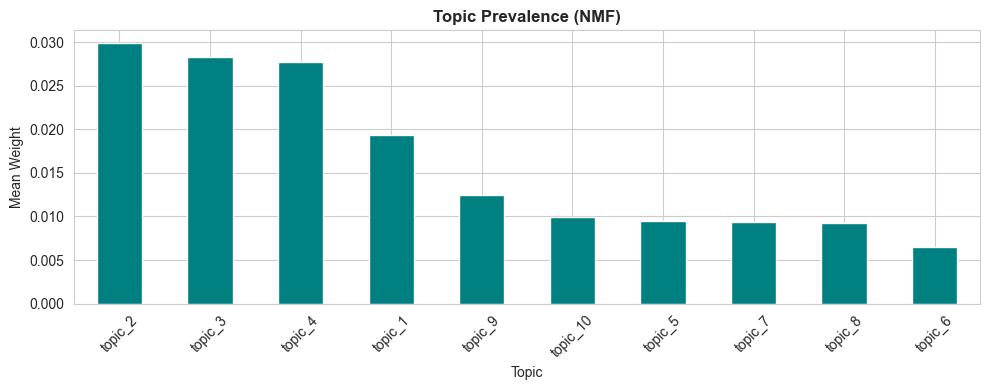

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
prevalence.plot(kind='bar', ax=ax, color='teal', edgecolor='white')
ax.set_title('Topic Prevalence (NMF)', fontweight='bold')
ax.set_ylabel('Mean Weight')
ax.set_xlabel('Topic')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_topic_prevalence.png')
plt.show()

## 10. Topic ↔ Category Alignment

Cross-tabulate dominant topic against the ground-truth threat category. Strong alignment suggests topics capture meaningful threat distinctions.

In [15]:
ct = pd.crosstab(doc_topic_df['dominant_topic'], df['category'])
print('Dominant Topic vs Category:')
print(ct.to_string())

Dominant Topic vs Category:
category        Botnet  Credential Theft  DDoS  Data Breach  Insider Threat  Malware  Phishing  Ransomware  Vulnerability  Web Attack
dominant_topic                                                                                                                       
topic_1            223               164   222          205               0      227       169         233            207          28
topic_10             0                 0     0            0             442        0         0           0              0           0
topic_2            248               253   259          234             175      266       206         258            265         212
topic_3            252               228   264          250              96      236       246         274            263         198
topic_4            237               240   256          252             220      247       238         242            260         252
topic_5              0            

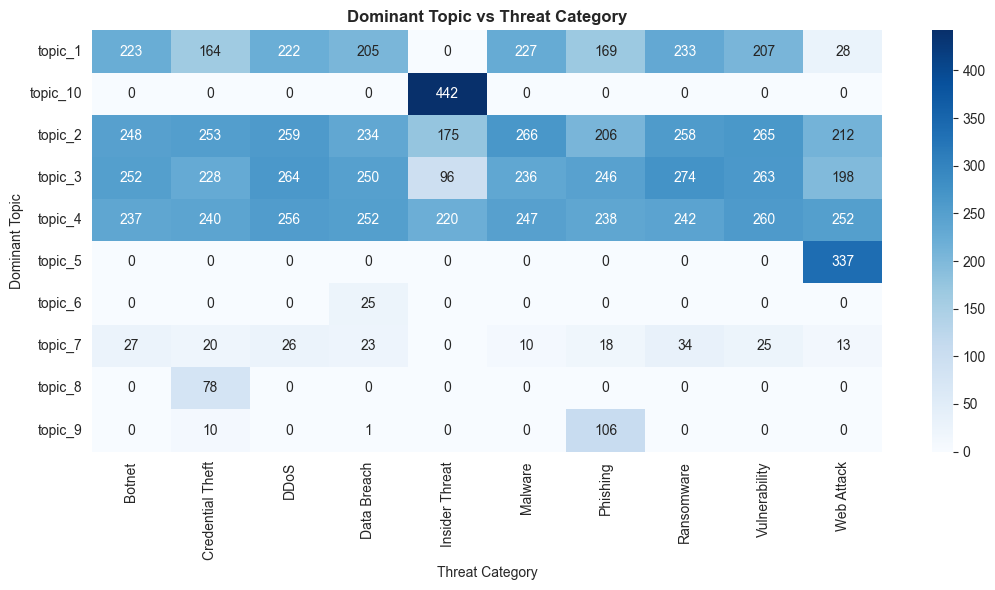

In [16]:
plt.figure(figsize=(11, 6))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Dominant Topic vs Threat Category', fontweight='bold')
plt.xlabel('Threat Category')
plt.ylabel('Dominant Topic')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_topic_category_heatmap.png')
plt.show()

<div class="callout"><b>Interpretation:</b> If a topic concentrates in one category, that topic captures a distinct threat type. Topics spread across many categories reflect generic cybersecurity vocabulary.</div>

## 11. Visualizations

### 11.1 Top Terms per Topic (NMF)

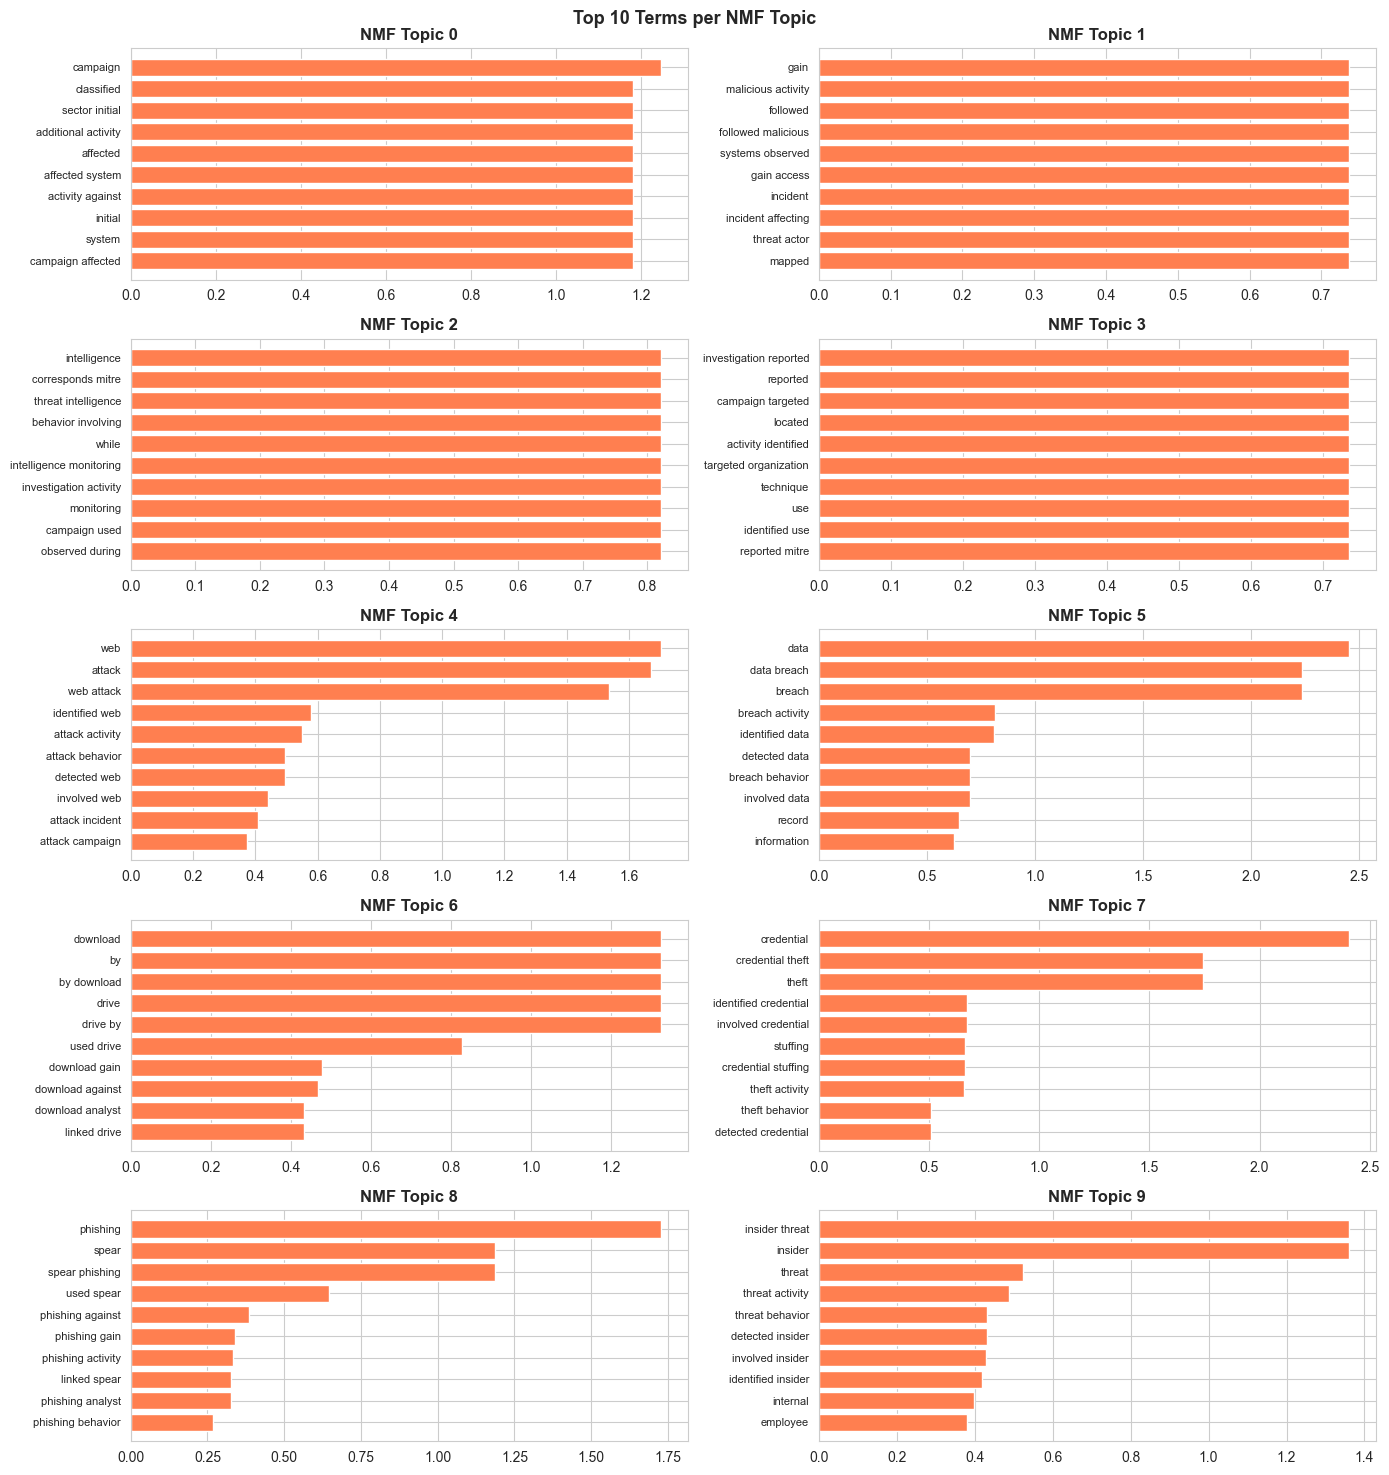

In [17]:
n_rows = (N_TOPICS + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 3 * n_rows))
axes = axes.flatten()

for i, terms in enumerate(nmf_topics):
    scores = nmf_model.components_[i]
    top_idx = np.argsort(scores)[::-1][:10]
    words = [vocab_nmf[j] for j in top_idx]
    vals  = [scores[j] for j in top_idx]
    axes[i].barh(range(len(words)), vals, color='coral')
    axes[i].set_yticks(range(len(words)))
    axes[i].set_yticklabels(words, fontsize=8)
    axes[i].invert_yaxis()
    axes[i].set_title(f'NMF Topic {i}', fontweight='bold')

for j in range(N_TOPICS, len(axes)):
    axes[j].axis('off')

plt.suptitle('Top 10 Terms per NMF Topic', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_nmf_top_terms.png')
plt.show()

### 11.2 Top Terms per Topic (LDA)

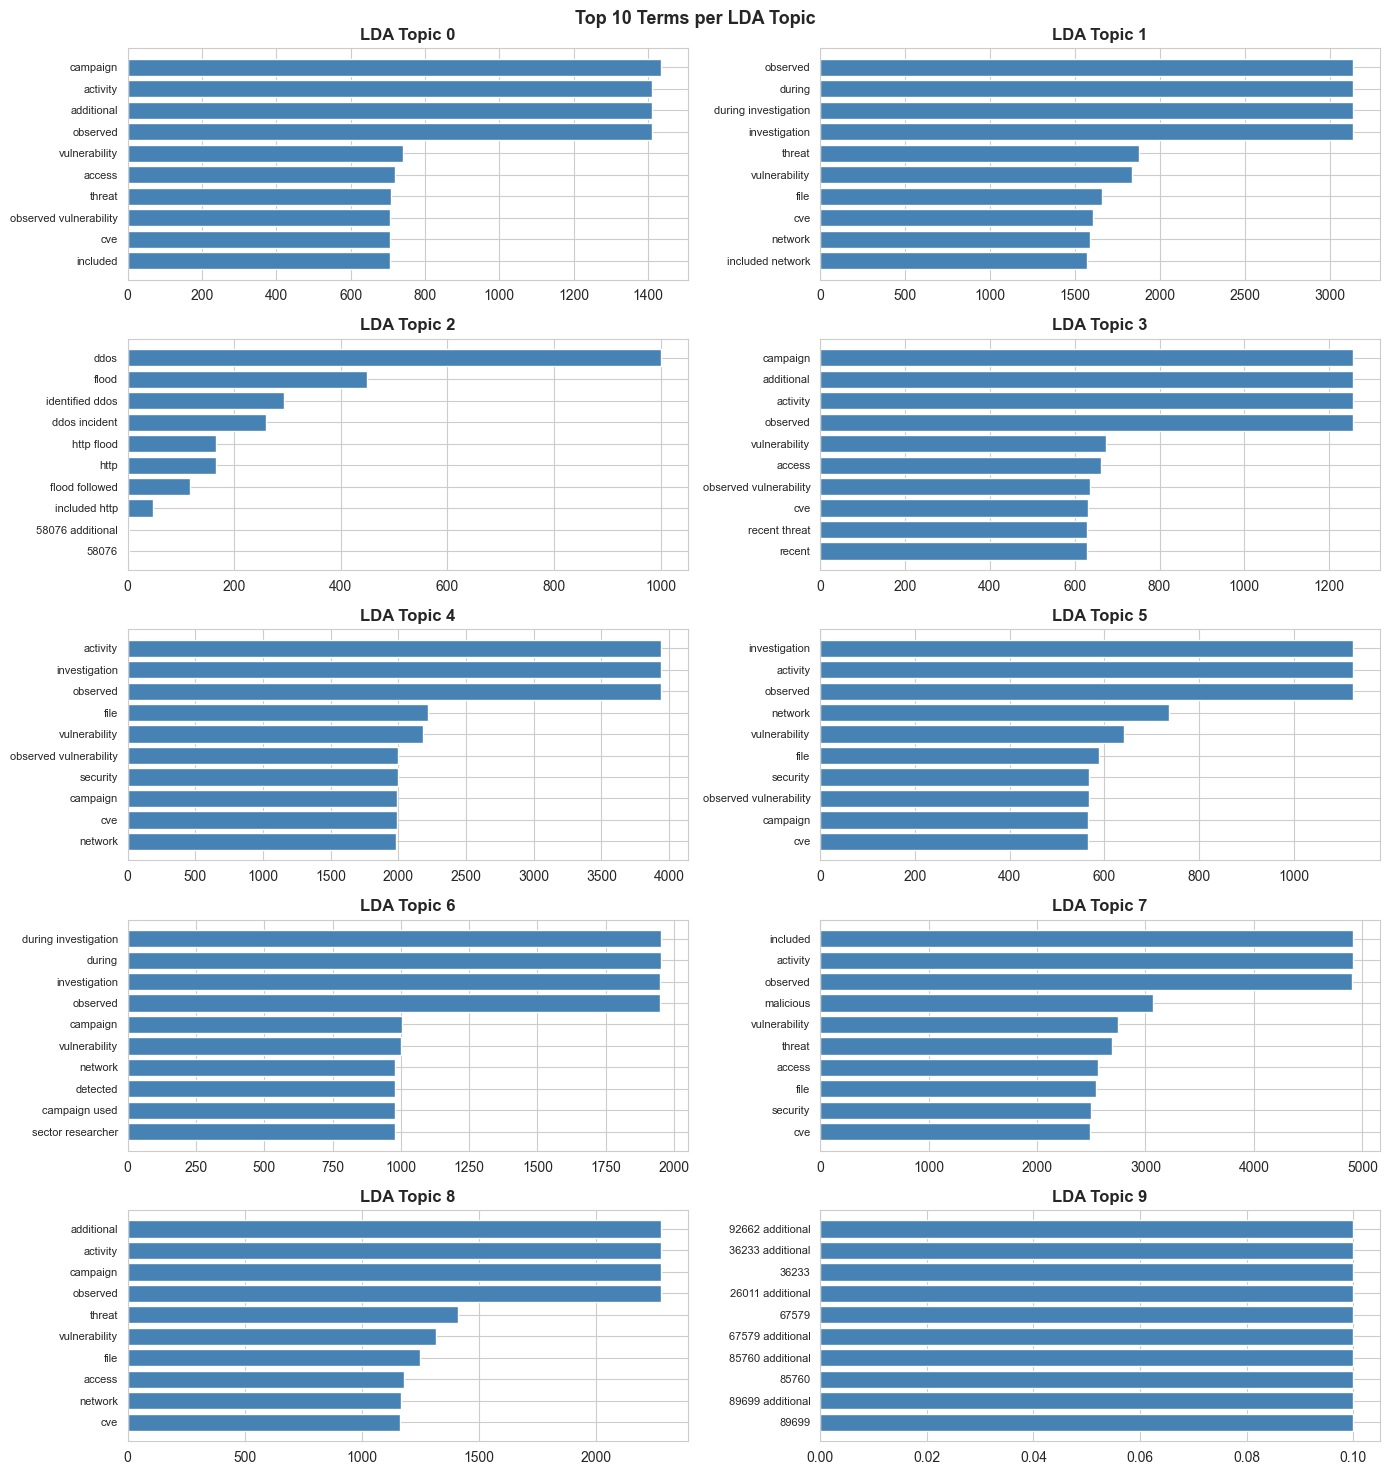

In [18]:
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 3 * n_rows))
axes = axes.flatten()

for i, terms in enumerate(lda_topics):
    scores = lda_model.components_[i]
    top_idx = np.argsort(scores)[::-1][:10]
    words = [vocab_lda[j] for j in top_idx]
    vals  = [scores[j] for j in top_idx]
    axes[i].barh(range(len(words)), vals, color='steelblue')
    axes[i].set_yticks(range(len(words)))
    axes[i].set_yticklabels(words, fontsize=8)
    axes[i].invert_yaxis()
    axes[i].set_title(f'LDA Topic {i}', fontweight='bold')

for j in range(N_TOPICS, len(axes)):
    axes[j].axis('off')

plt.suptitle('Top 10 Terms per LDA Topic', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_lda_top_terms.png')
plt.show()

## 12. Save Models & Topics

In [19]:
# Save topic tables
lda_rows = [{'topic': f'LDA_T{i}', 'top_terms': ', '.join(t)}
            for i, t in enumerate(lda_topics)]
pd.DataFrame(lda_rows).to_csv(TOPICS_DIR / 'lda_topics.csv', index=False)
print(f'Saved: {TOPICS_DIR / "lda_topics.csv"}')

nmf_rows = [{'topic': f'NMF_T{i}', 'top_terms': ', '.join(t)}
            for i, t in enumerate(nmf_topics)]
pd.DataFrame(nmf_rows).to_csv(TOPICS_DIR / 'nmf_topics.csv', index=False)
print(f'Saved: {TOPICS_DIR / "nmf_topics.csv"}')

# Save doc-topic distribution
doc_topic_df.to_csv(TOPICS_DIR / 'doc_topic_distribution.csv', index=False)
print(f'Saved: {TOPICS_DIR / "doc_topic_distribution.csv"}')

Saved: D:\Projects\done\thesis\Implementation\output\topics\lda_topics.csv
Saved: D:\Projects\done\thesis\Implementation\output\topics\nmf_topics.csv
Saved: D:\Projects\done\thesis\Implementation\output\topics\doc_topic_distribution.csv


In [20]:
# Save trained models + vectorizers
joblib.dump(lda_model, MODELS_DIR / 'lda_model.pkl')
joblib.dump(nmf_model, MODELS_DIR / 'nmf_model.pkl')
joblib.dump(vec_counts, MODELS_DIR / 'count_vectorizer.pkl')
joblib.dump(vec_tfidf, MODELS_DIR / 'tfidf_topic_vectorizer.pkl')

print(f'Saved LDA model        : {MODELS_DIR / "lda_model.pkl"}')
print(f'Saved NMF model        : {MODELS_DIR / "nmf_model.pkl"}')
print(f'Saved count vectorizer : {MODELS_DIR / "count_vectorizer.pkl"}')
print(f'Saved tfidf vectorizer : {MODELS_DIR / "tfidf_topic_vectorizer.pkl"}')

Saved LDA model        : D:\Projects\done\thesis\Implementation\output\models\lda_model.pkl
Saved NMF model        : D:\Projects\done\thesis\Implementation\output\models\nmf_model.pkl
Saved count vectorizer : D:\Projects\done\thesis\Implementation\output\models\count_vectorizer.pkl
Saved tfidf vectorizer : D:\Projects\done\thesis\Implementation\output\models\tfidf_topic_vectorizer.pkl


## 13. Summary

<div class="stat-grid"><div class="stat"><div class="value">K</div><div class="label">Topics per model</div></div><div class="stat"><div class="value">2</div><div class="label">Topic Models</div></div><div class="stat"><div class="value">V</div><div class="label">Vocabulary size</div></div><div class="stat"><div class="value">N</div><div class="label">Documents</div></div></div>

In [21]:
print('=== TOPIC MODELING SUMMARY ===')
print(f'Documents         : {len(docs):,}')
print(f'Vocabulary (LDA)  : {len(vocab_lda):,}')
print(f'Vocabulary (NMF)  : {len(vocab_nmf):,}')
print(f'Number of topics  : {N_TOPICS}')
print()
print('Artifacts saved:')
print(f'  - {TOPICS_DIR / "lda_topics.csv"}')
print(f'  - {TOPICS_DIR / "nmf_topics.csv"}')
print(f'  - {TOPICS_DIR / "doc_topic_distribution.csv"}')
print(f'  - {MODELS_DIR / "lda_model.pkl"}')
print(f'  - {MODELS_DIR / "nmf_model.pkl"}')
print()
if HAVE_GENSIM and coh_lda is not None:
    print(f'Coherence LDA : {coh_lda:.4f}')
    print(f'Coherence NMF : {coh_nmf:.4f}')

=== TOPIC MODELING SUMMARY ===
Documents         : 10,000
Vocabulary (LDA)  : 2,385
Vocabulary (NMF)  : 2,385
Number of topics  : 10

Artifacts saved:
  - D:\Projects\done\thesis\Implementation\output\topics\lda_topics.csv
  - D:\Projects\done\thesis\Implementation\output\topics\nmf_topics.csv
  - D:\Projects\done\thesis\Implementation\output\topics\doc_topic_distribution.csv
  - D:\Projects\done\thesis\Implementation\output\models\lda_model.pkl
  - D:\Projects\done\thesis\Implementation\output\models\nmf_model.pkl



<div class="callout"><b>Next step:</b> Proceed to <code>05_emerging_threats.ipynb</code> to compute temporal topic prevalence and emerging-threat scores.</div>

---
*End of topic modeling notebook.*